# Player baseline: historical production, season production, and minutes

Predict **points, rebounds, and assists conditional on playing**. Does a transparent per-minute blend improve on BPPS's existing model and a last-ten-game average?

Start with Stephen Curry. Full prior-career and previous-three-season rates compete; neither includes current-season games. Proposed blends exclude opponent adjustments; the existing application benchmark retains its adjustments. This notebook does not change application behavior or calibrate ranges.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from bpps.baseline_research import (
    RESEARCH_STATS,
    load_history,
    run_experiment,
    save_results,
)
from bpps.settings import PROJECT_ROOT

## 1. Choose data and evaluation periods

`nba` retrieves real regular-season games. Complete CSV snapshots are reused until `REFRESH=True`. Every requested season must be fetched successfully; an empty season is reported, while an upstream failure stops the experiment.

`csv` accepts the project's game-log schema; supply all requested seasons for a genuine career comparison. `synthetic` is an explicit deterministic multi-season **workflow check**, not evidence of NBA accuracy. Research sources are independent of application `STUB_MODE`.

For another player, change the player ID and first career season. Tuning seasons must precede the holdout. A career label assumes the supplied data actually covers that career.


In [2]:
DATA_SOURCE = "nba"  # "nba", "csv", or "synthetic"
PLAYER_ID = "201939"  # Stephen Curry
FIRST_SEASON = 2009
LAST_SEASON = 2025
CSV_PATH = None  # e.g. PROJECT_ROOT / "history.csv"
REFRESH = False
TUNING_SEASONS = (2023, 2024)
HOLDOUT_SEASON = 2025
CACHE_DIR = PROJECT_ROOT / ".cache" / "bpps" / "research"

In [3]:
dataset = load_history(
    player_id=PLAYER_ID,
    start=FIRST_SEASON,
    end=LAST_SEASON,
    source=DATA_SOURCE,
    csv_path=CSV_PATH,
    refresh=REFRESH,
    cache_dir=CACHE_DIR,
)
print(f"Source: {dataset.source} | Player: {dataset.player_id}")
print(f"Dataset SHA-256: {dataset.sha256}")
if dataset.source == "synthetic":
    print("SYNTHETIC DATA: workflow verification, not NBA predictive accuracy.")
display(pd.DataFrame(dataset.summary()))

Source: nba | Player: 201939
Dataset SHA-256: 1c4cc3f072fd0aee29355a9d3c5c43a55f96dfbc7c6460da49a5638ebae39d1f


,season,appearances,positive_minutes
0,2009-10,80,80
1,2010-11,74,74
2,2011-12,26,25
3,2012-13,78,78
4,2013-14,78,78
5,2014-15,80,80
6,2015-16,79,79
7,2016-17,79,79
8,2017-18,51,51
9,2018-19,69,69


## 2. Define the baseline before evaluating it

Rate = **total production / total minutes**, not the mean of individual game rates. Exclude zero-minute appearances. Every feature uses dates strictly earlier than the target; require at least five earlier appearances.

**Prediction = [(1 − w) × historical rate + w × season rate] × expected minutes.**

Expected minutes = mean of the last ten positive-minute appearances, capped at 48. If fewer than ten exist, use all available. Historical windows are all prior seasons or the previous three. If only one rate component exists, use it alone.

Candidates: fixed season weights `0, 0.25, 0.5, 0.75, 1`; adaptive weights `season_minutes / (season_minutes + k)` for `k = 100, 300, 600, 1200`.

Choose lowest pooled tuning MAE independently for each stat. Exact ties favor previous-three-season history, then fixed weights ascending, then adaptive constants ascending. Selection precedes holdout feature construction. Earlier holdout games update subsequent history but never retune parameters. Actual target-game minutes are used only for evaluation.


In [4]:
experiment = run_experiment(dataset, TUNING_SEASONS, HOLDOUT_SEASON)
selection = pd.DataFrame(
    [
        {
            "stat": stat,
            "window": candidate.window,
            "kind": candidate.kind,
            "value": candidate.value,
        }
        for stat, candidate in experiment.selected.items()
    ]
)
display(selection)
tuning = pd.DataFrame(experiment.tuning_scores)
display(tuning.sort_values(["stat", "mae"], kind="stable").round(3))

,stat,window,kind,value
0,points,previous_three,fixed,0.25
1,rebounds,career,fixed,0.00
2,assists,previous_three,fixed,0.25


,stat,method,mae,rmse,evaluated_games
41,assists,previous_three/fixed/0.25,2.023,2.586,144
50,assists,career/fixed/0.25,2.044,2.616,144
42,assists,previous_three/fixed/0.5,2.045,2.599,144
48,assists,previous_three/adaptive/1200,2.046,2.595,144
40,assists,previous_three/fixed/0,2.046,2.622,144
51,assists,career/fixed/0.5,2.054,2.614,144
47,assists,previous_three/adaptive/600,2.055,2.594,144
57,assists,career/adaptive/1200,2.057,2.614,144
46,assists,previous_three/adaptive/300,2.062,2.599,144
56,assists,career/adaptive/600,2.064,2.607,144


## 3. Evaluate on the later holdout season

All methods use identical eligible games. **MAE** measures average absolute error; **RMSE** gives large misses more weight. Minutes errors help distinguish playing-time uncertainty from production uncertainty.

Positive improvement means the blend reduced MAE; negative means it lost. Small differences from one player's single season should be interpreted cautiously.


In [5]:
holdout = pd.DataFrame(experiment.holdout_scores)
predictions = pd.DataFrame(experiment.predictions)
predictions["date"] = pd.to_datetime(predictions["date"])
display(holdout.round(3))
display(pd.DataFrame(experiment.minutes_scores).round(3))
comparison = holdout.pivot(index="stat", columns="method", values="mae")
comparison["improvement_vs_existing"] = (
    comparison["existing"] - comparison["selected_blend"]
)
comparison["improvement_vs_last_ten"] = (
    comparison["last_ten"] - comparison["selected_blend"]
)
display(comparison.round(3))
for stat in RESEARCH_STATS:
    row = comparison.loc[stat]
    for benchmark in ("existing", "last_ten"):
        difference = row[benchmark] - row["selected_blend"]
        verdict = "wins" if difference > 0 else "loses" if difference < 0 else "ties"
        print(
            f"{stat.title()}: blend {verdict} vs {benchmark}; MAE improvement {difference:.3f}"
        )
if dataset.source == "synthetic":
    print("These conclusions concern synthetic fixtures only.")

,stat,method,mae,rmse,evaluated_games
0,points,selected_blend,7.851,10.329,43
1,points,existing,8.018,10.255,43
2,points,last_ten,8.079,10.366,43
3,rebounds,selected_blend,1.865,2.250,43
4,rebounds,existing,1.676,2.132,43
5,rebounds,last_ten,1.765,2.258,43
6,assists,selected_blend,2.058,2.535,43
7,assists,existing,2.162,2.663,43
8,assists,last_ten,2.188,2.706,43


,stat,method,mae,rmse,evaluated_games
0,minutes,estimated_minutes,3.123,3.944,43
1,minutes,existing_minutes,3.277,4.088,43


method,existing,last_ten,selected_blend,improvement_vs_existing,improvement_vs_last_ten
stat,,,,,
assists,2.162,2.188,2.058,0.103,0.130
points,8.018,8.079,7.851,0.168,0.228
rebounds,1.676,1.765,1.865,-0.189,-0.100


Points: blend wins vs existing; MAE improvement 0.168
Points: blend wins vs last_ten; MAE improvement 0.228
Rebounds: blend loses vs existing; MAE improvement -0.189
Rebounds: blend loses vs last_ten; MAE improvement -0.100
Assists: blend wins vs existing; MAE improvement 0.103
Assists: blend wins vs last_ten; MAE improvement 0.130


## 4. Inspect the estimates

Figures show pregame rates and minutes estimates alongside outcomes. All plots are saved as standalone PNGs alongside the results.


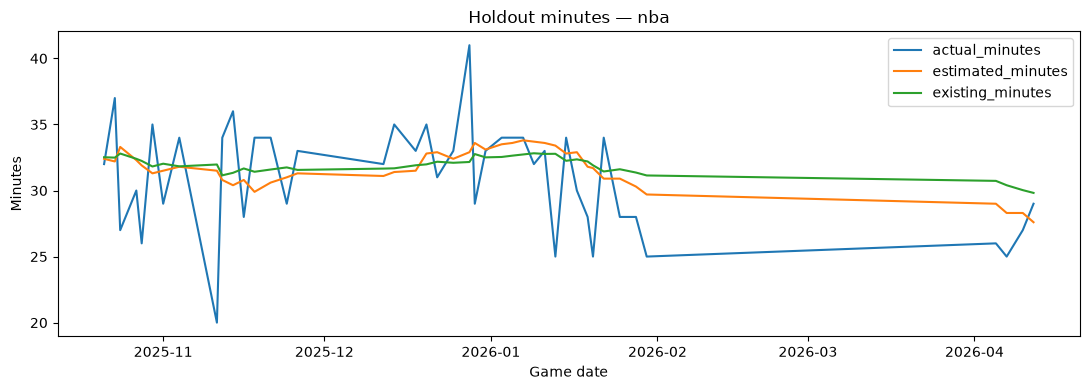

In [6]:
output_dir = save_results(dataset, experiment, CACHE_DIR)
minutes = predictions.query("stat == 'points' and method == 'selected_blend'")
fig, ax = plt.subplots(figsize=(11, 4))
for column in ("actual_minutes", "estimated_minutes", "existing_minutes"):
    ax.plot(minutes["date"], minutes[column], label=column)
ax.set(
    title=f"Holdout minutes — {dataset.source}", ylabel="Minutes", xlabel="Game date"
)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "minutes.png", dpi=150)
plt.show()
plt.close(fig)

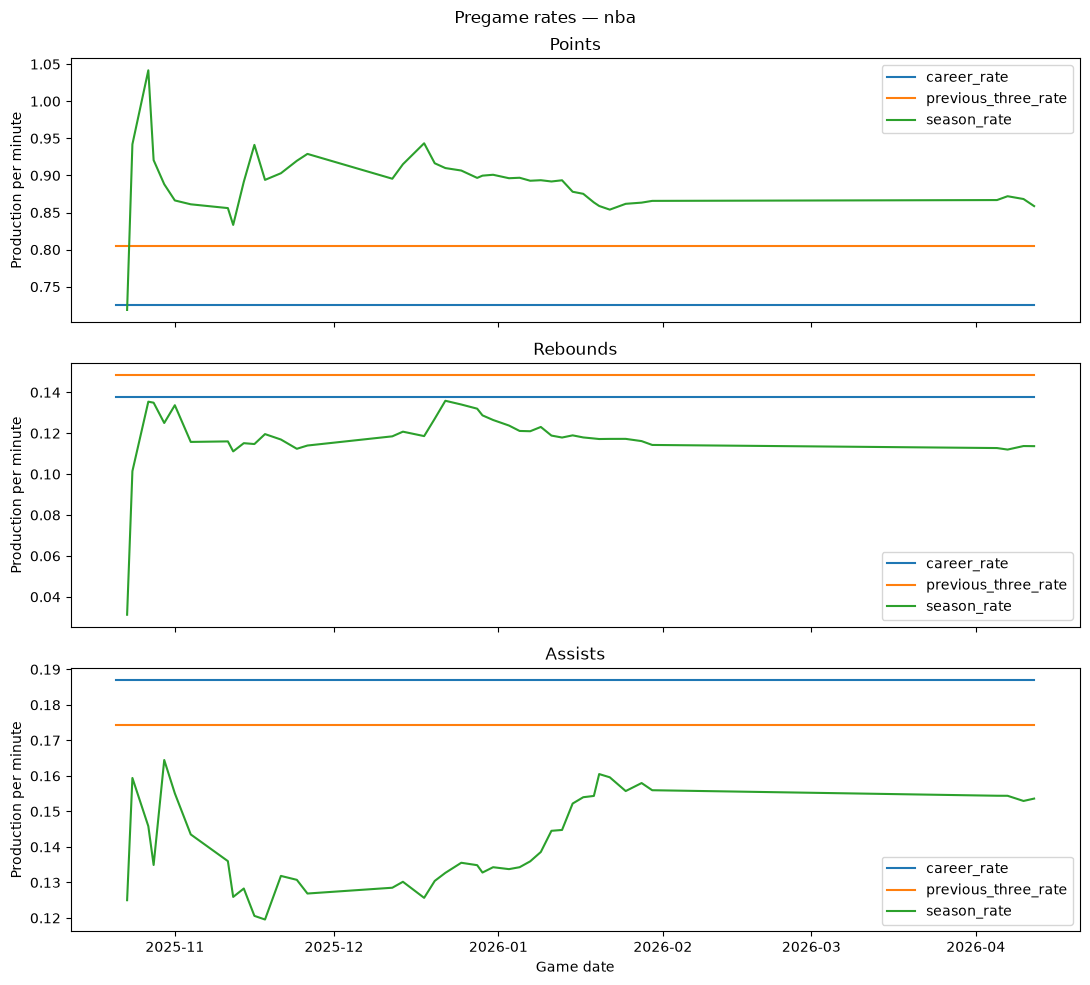

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, stat in zip(axes, RESEARCH_STATS, strict=True):
    data = predictions.query("stat == @stat and method == 'selected_blend'")
    for column in ("career_rate", "previous_three_rate", "season_rate"):
        ax.plot(data["date"], data[column], label=column)
    ax.set(title=stat.title(), ylabel="Production per minute")
    ax.legend()
axes[-1].set_xlabel("Game date")
fig.suptitle(f"Pregame rates — {dataset.source}")
fig.tight_layout()
fig.savefig(output_dir / "rates.png", dpi=150)
plt.show()
plt.close(fig)

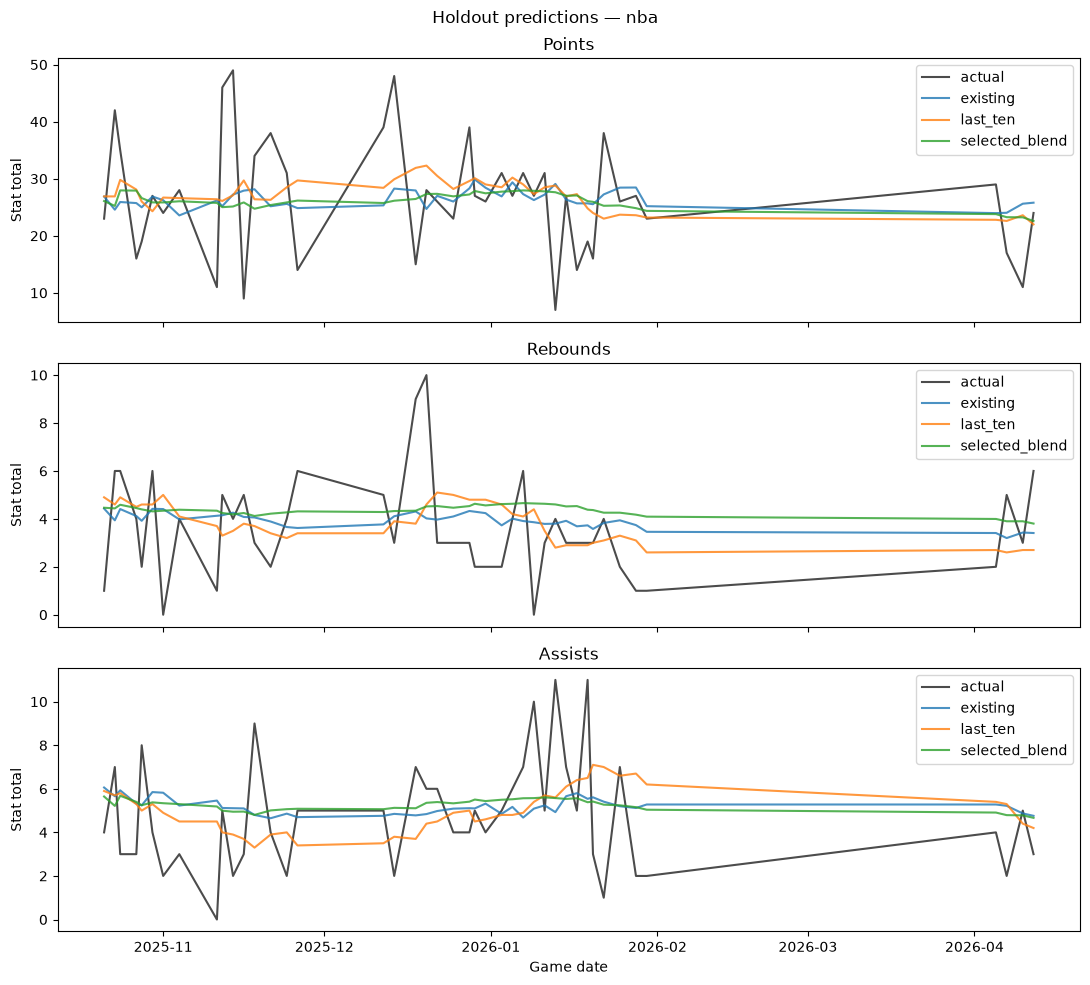

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, stat in zip(axes, RESEARCH_STATS, strict=True):
    data = predictions.query("stat == @stat")
    actual = data.query("method == 'selected_blend'")
    ax.plot(actual["date"], actual["actual"], color="black", label="actual", alpha=0.7)
    for method, group in data.groupby("method"):
        ax.plot(group["date"], group["prediction"], label=method, alpha=0.8)
    ax.set(title=stat.title(), ylabel="Stat total")
    ax.legend()
axes[-1].set_xlabel("Game date")
fig.suptitle(f"Holdout predictions — {dataset.source}")
fig.tight_layout()
fig.savefig(output_dir / "predictions.png", dpi=150)
plt.show()
plt.close(fig)

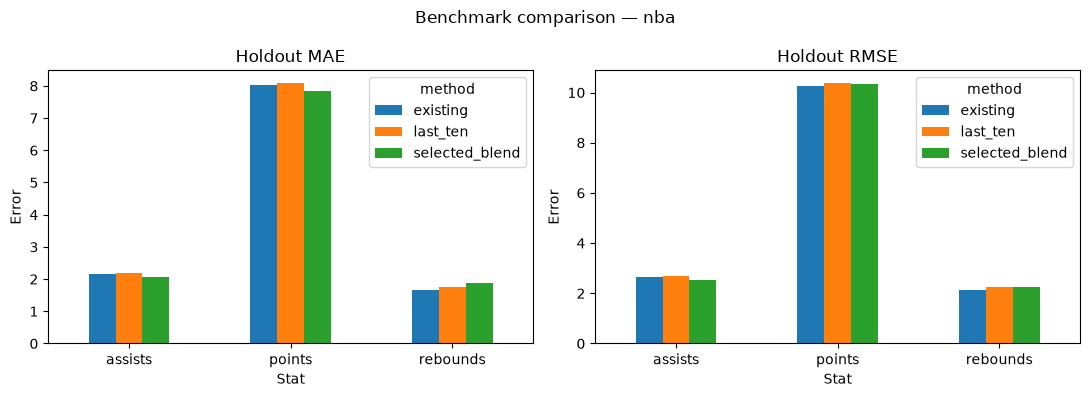

Results and plots: /home/segfaultering/projects/basketball-performance-prediction-system/.cache/bpps/research/results-02022f501a0fe471


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ("mae", "rmse"), strict=True):
    holdout.pivot(index="stat", columns="method", values=metric).plot.bar(ax=ax)
    ax.set(title=f"Holdout {metric.upper()}", ylabel="Error", xlabel="Stat")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle(f"Benchmark comparison — {dataset.source}")
fig.tight_layout()
fig.savefig(output_dir / "errors.png", dpi=150)
plt.show()
plt.close(fig)
print(f"Results and plots: {output_dir}")

## 5. Interpret the findings

Check whether the blend beats **both** benchmarks for each stat. A winner for points need not win for rebounds or assists. Inspect minutes error and large misses before attributing differences to blending weights.

The notebook creates an auditable baseline for future ML models; it does not model injuries or roles or change the API. Any further tuning after inspecting this holdout requires a new untouched evaluation period. Synthetic results establish only that the workflow executes.
